In [27]:
# Import das bibliotecas

import pandas as pd 
import scipy 

### Preparação dos Dados

- Nesta etapa iremos visualizar as estruturas dos dados, manter somente o necessário e com isso realizar o cruzamento para obtermos nosso Dataset.

In [2]:
# Agregar as interações por livro (o CSV tem ~228M linhas / 4.3 GB, então
# processamos em chunks em vez de carregar tudo em memória). A coluna
# "book_id" aqui é na verdade o book_id_csv (índice), mapeado depois.
dtypes = {'user_id': 'int32', 'book_id': 'int32', 'is_read': 'int8',
          'rating': 'int8', 'is_reviewed': 'int8'}

agg = None
for chunk in pd.read_csv('goodreads_interactions.csv', dtype=dtypes, chunksize=2_000_000):
    chunk['is_rated'] = chunk['rating'] > 0
    part = chunk.groupby('book_id').agg(
        n_interactions=('user_id', 'size'),
        n_read=('is_read', 'sum'),
        n_reviewed=('is_reviewed', 'sum'),
        n_rated=('is_rated', 'sum'),
        rating_sum=('rating', 'sum'),
    )
    agg = part if agg is None else agg.add(part, fill_value=0)

agg['user_avg_rating'] = agg['rating_sum'] / agg['n_rated']
agg = agg.drop(columns='rating_sum').reset_index().rename(columns={'book_id': 'book_id_csv'})
agg.head(10)

,book_id_csv,n_interactions,n_read,n_reviewed,n_rated,user_avg_rating
0,0,895.0,50.0,7.0,14.0,4.285714
1,1,215.0,50.0,3.0,19.0,3.947368
2,2,128.0,6.0,1.0,1.0,3.000000
3,3,1663.0,630.0,71.0,514.0,4.249027
4,4,34.0,11.0,1.0,4.0,4.500000
5,5,326.0,18.0,2.0,11.0,3.909091
6,6,252.0,28.0,6.0,21.0,3.666667
7,7,4369.0,445.0,102.0,244.0,3.733607
8,8,109.0,46.0,10.0,36.0,3.805556
9,9,223.0,58.0,8.0,50.0,4.080000


In [3]:
# book_id no CSV de interações é o índice (book_id_csv); mapeamos para o
# book_id real do goodreads_books usando o mapa fornecido.
book_id_map = pd.read_csv('book_id_map.csv')
interactions_data = agg.merge(book_id_map, on='book_id_csv', how='left').drop(columns='book_id_csv')
interactions_data.head(10)

,n_interactions,n_read,n_reviewed,n_rated,user_avg_rating,book_id
0,895.0,50.0,7.0,14.0,4.285714,34684622
1,215.0,50.0,3.0,19.0,3.947368,34536488
2,128.0,6.0,1.0,1.0,3.000000,34017076
3,1663.0,630.0,71.0,514.0,4.249027,71730
4,34.0,11.0,1.0,4.0,4.500000,30422361
5,326.0,18.0,2.0,11.0,3.909091,33503613
6,252.0,28.0,6.0,21.0,3.666667,33517540
7,4369.0,445.0,102.0,244.0,3.733607,34467031
8,109.0,46.0,10.0,36.0,3.805556,6383669
9,223.0,58.0,8.0,50.0,4.080000,486625


In [4]:
# Carregar o Json de Livros e manter apenas o necessário

KEEP = ['book_id', 'work_id', 'title', 'average_rating', 'ratings_count',
        'text_reviews_count', 'num_pages', 'publication_year', 'is_ebook',
        'authors', 'primary_author']

books = pd.read_parquet('books.parquet', columns=KEEP)
books.head(10)

,book_id,work_id,title,average_rating,ratings_count,text_reviews_count,num_pages,publication_year,is_ebook,authors,primary_author
0,5333265,5400751.0,W.C. Fields: A Life on Film,4.00,3.0,1.0,256.0,1984.0,False,[604031],604031.0
1,1333909,1323437.0,Good Harbor,3.23,10.0,6.0,NaN,2001.0,False,[626222],626222.0
2,7327624,8948723.0,"The Unschooled Wizard (Sun Wolf and Starhawk, ...",4.03,140.0,7.0,600.0,1987.0,False,[10333],10333.0
3,6066819,6243154.0,Best Friends Forever,3.49,51184.0,3282.0,368.0,2009.0,False,[9212],9212.0
4,287140,278577.0,Runic Astrology: Starcraft and Timekeeping in ...,3.40,15.0,5.0,NaN,NaN,False,[149918],149918.0
5,287141,278578.0,The Aeneid for Boys and Girls,4.13,46.0,7.0,162.0,2006.0,False,[3041852],3041852.0
6,378460,368291.0,The Wanting of Levine,4.38,12.0,4.0,NaN,1979.0,False,[215594],215594.0
7,6066812,701117.0,All's Fairy in Love and War (Avalon: Web of Ma...,4.22,98.0,6.0,216.0,2009.0,False,[19158],19158.0
8,34883016,56135087.0,Playmaker: A Venom Series Novella,3.86,5.0,4.0,NaN,2017.0,True,[5807700],5807700.0
9,287149,278586.0,The Devil's Notebook,3.81,986.0,39.0,147.0,2000.0,False,"[2983296, 40075]",2983296.0


In [5]:
# Manter apenas um autor por livro
# primary_author já vem do parquet: o primeiro autor com role vazio
# (nulo quando o livro só credita editor/contribuidor).
primary = (books[['book_id', 'primary_author']]
           .dropna(subset=['primary_author'])
           .rename(columns={'primary_author': 'author_id'})
           .astype({'author_id': 'int64'}))
primary.head(10)

,book_id,author_id
0,5333265,604031
1,1333909,626222
2,7327624,10333
3,6066819,9212
4,287140,149918
5,287141,3041852
6,378460,215594
7,6066812,19158
8,34883016,5807700
9,287149,2983296


In [6]:
g = pd.read_json('./goodreads_book_genres_initial/goodreads_book_genres_initial.json',
                 lines=True)
genres = pd.concat([g[['book_id']], pd.json_normalize(g['genres'])], axis=1).fillna(0)
genres.head(10)


,book_id,"history, historical fiction, biography",fiction,"fantasy, paranormal","mystery, thriller, crime",poetry,romance,non-fiction,children,young-adult,"comics, graphic"
0,5333265,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1333909,5.0,219.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,7327624,0.0,8.0,31.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
3,6066819,0.0,555.0,0.0,10.0,0.0,23.0,0.0,0.0,0.0,0.0
4,287140,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0
5,287141,9.0,1.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0,0.0
6,378460,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,6066812,0.0,7.0,32.0,0.0,0.0,0.0,0.0,16.0,8.0,0.0
8,34883016,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0
9,287149,1.0,0.0,0.0,0.0,0.0,0.0,24.0,0.0,0.0,0.0


In [7]:
authors = pd.read_json('./goodreads_book_authors//goodreads_book_authors.json', lines=True)
authors.head(10)

,average_rating,author_id,text_reviews_count,name,ratings_count
0,3.98,604031,7,Ronald J. Fields,49
1,4.08,626222,28716,Anita Diamant,546796
2,3.92,10333,5075,Barbara Hambly,122118
3,3.68,9212,36262,Jennifer Weiner,888522
4,3.82,149918,96,Nigel Pennick,1740
5,3.89,3041852,85,Alfred J. Church,947
6,4.17,215594,6,Michael Halberstam,23
7,4.18,19158,486,Rachel Roberts,13677
8,3.99,5807700,986,V.L. Locey,3130
9,3.48,2983296,824,Anton Szandor LaVey,12628


In [8]:
# Criando o Dataframe para o modelo 

books_df = (books.drop(columns=['authors', 'primary_author'])
                .merge(primary, on='book_id', how='left')
                .merge(authors.rename(columns={'average_rating': 'author_avg_rating',
                                                'ratings_count' : 'author_ratings_count'}),
                        on='author_id', how='left')
                .merge(genres, on='book_id', how='left')
                .merge(interactions_data, on='book_id', how='left'))

# Livros sem nenhuma interação no CSV viram NaN nas contagens: são
# genuinamente zero interações, então preenchemos apenas essas colunas
# (user_avg_rating fica NaN de propósito, pois "sem avaliação" != 0).
count_cols = ['n_interactions', 'n_read', 'n_reviewed', 'n_rated']
books_df[count_cols] = books_df[count_cols].fillna(0)

In [9]:
# Visualização dos 5 primeiros registros
books_df.head(5)

,book_id,work_id,title,average_rating,ratings_count,text_reviews_count_x,num_pages,publication_year,is_ebook,author_id,...,romance,non-fiction,children,young-adult,"comics, graphic",n_interactions,n_read,n_reviewed,n_rated,user_avg_rating
0,5333265,5400751.0,W.C. Fields: A Life on Film,4.00,3.0,1.0,256.0,1984.0,False,604031.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,4.000000
1,1333909,1323437.0,Good Harbor,3.23,10.0,6.0,NaN,2001.0,False,626222.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,2.000000
2,7327624,8948723.0,"The Unschooled Wizard (Sun Wolf and Starhawk, ...",4.03,140.0,7.0,600.0,1987.0,False,10333.0,...,0.0,0.0,0.0,0.0,0.0,58.0,27.0,3.0,26.0,3.961538
3,6066819,6243154.0,Best Friends Forever,3.49,51184.0,3282.0,368.0,2009.0,False,9212.0,...,23.0,0.0,0.0,0.0,0.0,6510.0,3920.0,451.0,3749.0,3.386770
4,287140,278577.0,Runic Astrology: Starcraft and Timekeeping in ...,3.40,15.0,5.0,NaN,NaN,False,149918.0,...,0.0,3.0,0.0,0.0,0.0,6.0,1.0,1.0,1.0,5.000000


In [10]:
# Visualização dos 5 ultimos registros
books_df.tail(10)

,book_id,work_id,title,average_rating,ratings_count,text_reviews_count_x,num_pages,publication_year,is_ebook,author_id,...,romance,non-fiction,children,young-adult,"comics, graphic",n_interactions,n_read,n_reviewed,n_rated,user_avg_rating
2360645,331839,25313618.0,Jacqueline Kennedy Onassis: Friend of the Arts,4.36,18.0,1.0,176.0,2002.0,False,10681.0,...,0.0,0.0,3.0,0.0,0.0,10.0,3.0,1.0,3.0,4.666667
2360646,17061397,19319808.0,Jesus and Scripture,2.83,3.0,2.0,105.0,2011.0,True,740349.0,...,0.0,0.0,0.0,0.0,0.0,5.0,2.0,1.0,1.0,4.000000
2360647,2685097,2710420.0,The Spaniard's Blackmailed Bride,3.42,112.0,9.0,192.0,2007.0,False,319441.0,...,10.0,0.0,0.0,0.0,0.0,49.0,29.0,2.0,28.0,3.392857
2360648,18069148,25365816.0,Different Breeds,2.00,2.0,3.0,NaN,2013.0,True,5344314.0,...,1.0,0.0,0.0,0.0,0.0,3.0,2.0,2.0,1.0,2.000000
2360649,30244126,10351024.0,Herança,3.86,6.0,2.0,336.0,2016.0,False,14255.0,...,80.0,0.0,0.0,0.0,0.0,3.0,3.0,2.0,3.0,3.000000
2360650,3084038,3115103.0,"This Sceptred Isle, Vol. 10: The Age of Victor...",4.05,12.0,3.0,3.0,1999.0,False,4015.0,...,0.0,5.0,0.0,0.0,0.0,3.0,2.0,1.0,2.0,3.500000
2360651,26168430,46130263.0,Sherlock Holmes and the July Crisis,3.50,6.0,2.0,148.0,2015.0,False,2448.0,...,0.0,0.0,1.0,0.0,0.0,194.0,4.0,1.0,4.0,3.250000
2360652,2342551,2349247.0,The Children's Classic Poetry Collection,4.00,36.0,6.0,96.0,1996.0,False,NaN,...,0.0,1.0,7.0,1.0,0.0,6.0,6.0,1.0,6.0,3.833333
2360653,22017381,41332799.0,"101 Nights: Volume One (101 Nights, #1-3)",4.37,70.0,17.0,306.0,2014.0,False,7789809.0,...,13.0,0.0,0.0,0.0,0.0,92.0,13.0,3.0,13.0,4.307692
2360654,11419866,2206102.0,The Spanish Duke's Virgin Bride (Innocent Mist...,3.52,7.0,1.0,NaN,NaN,True,621880.0,...,19.0,0.0,0.0,0.0,0.0,3.0,2.0,1.0,2.0,3.000000


In [11]:
# Visualização da Estrutura do DataFrame (Informativo)
books_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2360655 entries, 0 to 2360654
Data columns (total 29 columns):
 #   Column                                  Dtype  
---  ------                                  -----  
 0   book_id                                 int64  
 1   work_id                                 float64
 2   title                                   str    
 3   average_rating                          float32
 4   ratings_count                           float64
 5   text_reviews_count_x                    float64
 6   num_pages                               float64
 7   publication_year                        float64
 8   is_ebook                                bool   
 9   author_id                               float64
 10  author_avg_rating                       float64
 11  text_reviews_count_y                    float64
 12  name                                    str    
 13  author_ratings_count                    float64
 14  history, historical fiction, biography  float

### Análise Exploratória dos Dados

- Nesta parte iremos realizar uma análise exploratória dos dados para entender melhor a estrutura dos dados e como eles se comportam.

In [12]:
import matplotlib.pyplot as plt

# Estatísticas descritivas das variáveis numéricas
books_df.describe()

,book_id,work_id,average_rating,ratings_count,text_reviews_count_x,num_pages,publication_year,author_id,author_avg_rating,text_reviews_count_y,...,romance,non-fiction,children,young-adult,"comics, graphic",n_interactions,n_read,n_reviewed,n_rated,user_avg_rating
count,2.360655e+06,2.360131e+06,2.360131e+06,2.360131e+06,2.360131e+06,1.596522e+06,1.761016e+06,2.305673e+06,2.305673e+06,2.305673e+06,...,2.360655e+06,2.360655e+06,2.360655e+06,2.360655e+06,2.360655e+06,2.360655e+06,2.360655e+06,2.360655e+06,2.360655e+06,2.325541e+06
mean,1.540953e+07,2.074911e+07,3.865792e+00,4.063074e+02,2.808668e+01,2.635639e+02,2.007109e+03,3.235245e+06,3.891461e+00,7.395111e+03,...,3.521989e+01,2.036648e+01,2.446449e+01,4.818515e+01,8.097222e+00,9.685801e+01,4.750004e+01,6.870614e+00,4.428921e+01,3.841529e+00
std,1.081897e+07,1.911737e+07,5.406798e-01,1.112635e+04,3.787806e+02,8.298744e+02,1.716332e+02,4.242478e+06,3.906842e-01,2.965708e+04,...,2.763364e+02,2.587892e+02,3.490232e+02,6.140354e+02,1.793238e+02,1.223239e+03,8.489452e+02,6.607641e+01,8.194394e+02,7.345780e-01
min,1.000000e+00,4.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.000000e+00,0.000000e+00,0.000000e+00,...,-1.100000e+01,-5.000000e+00,-3.000000e+00,-1.100000e+01,-2.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
25%,5.979046e+06,2.163360e+06,3.630000e+00,6.000000e+00,2.000000e+00,1.470000e+02,2.004000e+03,6.890000e+04,3.720000e+00,2.400000e+01,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.000000e+00,2.000000e+00,1.000000e+00,2.000000e+00,3.500000e+00
50%,1.585681e+07,1.689600e+07,3.910000e+00,2.000000e+01,4.000000e+00,2.450000e+02,2.011000e+03,8.851280e+05,3.920000e+00,2.310000e+02,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.000000e+00,5.000000e+00,1.000000e+00,4.000000e+00,4.000000e+00
75%,2.438194e+07,4.203700e+07,4.160000e+00,7.700000e+01,1.100000e+01,3.440000e+02,2.014000e+03,5.579725e+06,4.100000e+00,2.222000e+03,...,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.400000e+01,1.400000e+01,3.000000e+00,1.300000e+01,4.285714e+00
max,3.653043e+07,5.837948e+07,5.000000e+00,4.899965e+06,1.426450e+05,9.450770e+05,3.201400e+04,1.733777e+07,5.000000e+00,4.485700e+05,...,1.020900e+04,1.548600e+04,1.548300e+04,3.018000e+04,1.597300e+04,3.146850e+05,2.856980e+05,2.085900e+04,2.811350e+05,5.000000e+00


In [13]:
# Percentual de valores ausentes por coluna
(books_df.isna().mean() * 100).sort_values(ascending=False).round(2)

num_pages                                 32.37
publication_year                          25.40
author_avg_rating                          2.33
author_id                                  2.33
text_reviews_count_y                       2.33
name                                       2.33
author_ratings_count                       2.33
user_avg_rating                            1.49
work_id                                    0.02
text_reviews_count_x                       0.02
ratings_count                              0.02
average_rating                             0.02
title                                      0.00
is_ebook                                   0.00
book_id                                    0.00
fiction                                    0.00
history, historical fiction, biography     0.00
mystery, thriller, crime                   0.00
poetry                                     0.00
romance                                    0.00
fantasy, paranormal                     

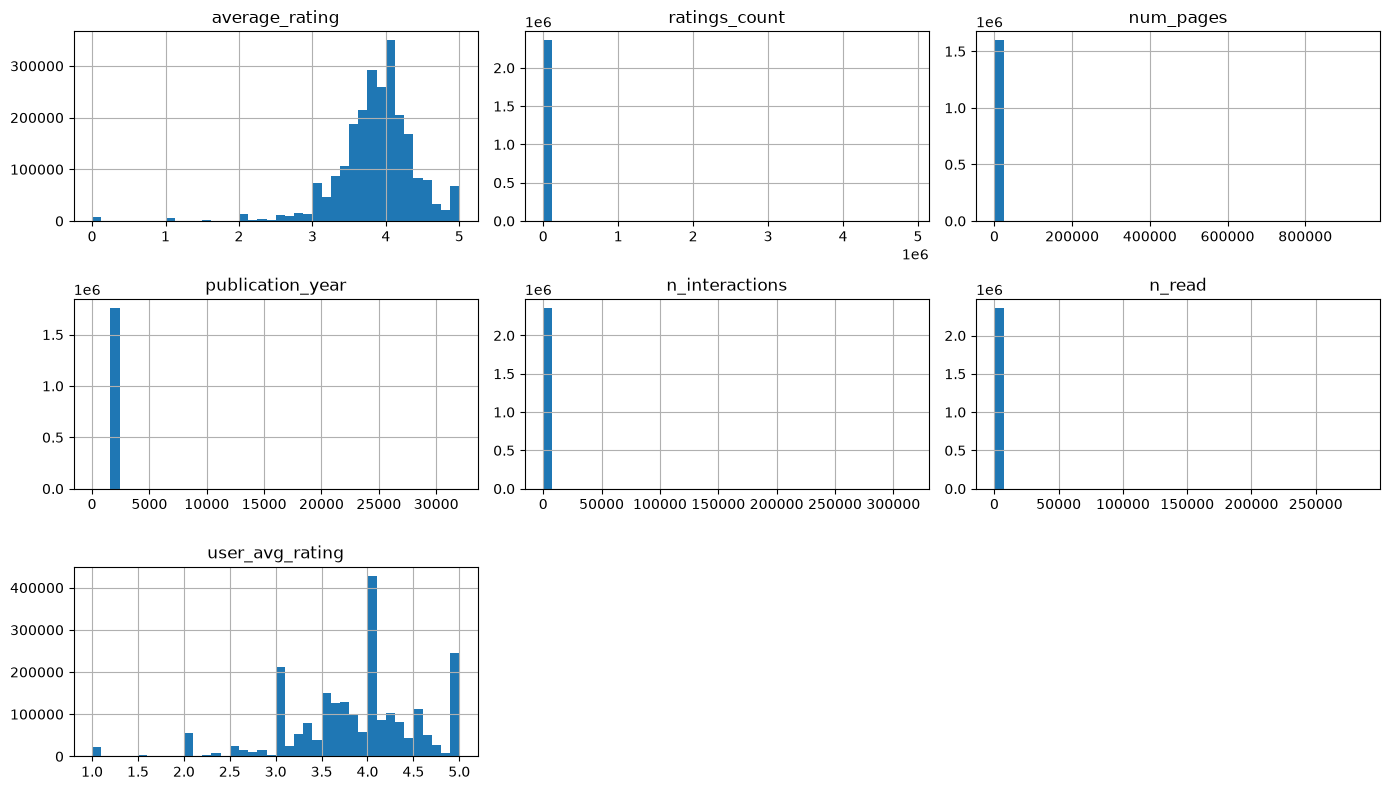

In [14]:
# Distribuição das principais variáveis numéricas
num_cols = ['average_rating', 'ratings_count', 'num_pages', 'publication_year',
            'n_interactions', 'n_read', 'user_avg_rating']
books_df[num_cols].hist(figsize=(14, 8), bins=40)
plt.tight_layout()
plt.show()

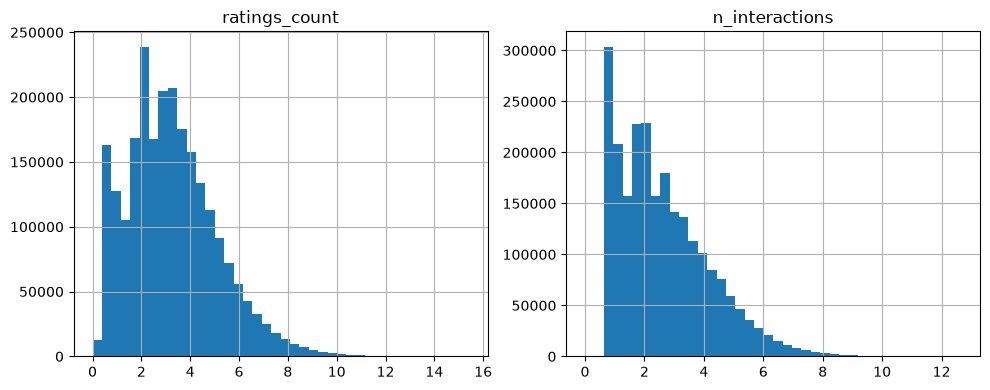

In [15]:
# ratings_count e n_interactions são muito assimétricos (poucos best-sellers
# dominam) -> olhar em escala log revela melhor a forma da distribuição
import numpy as np

log_cols = ['ratings_count', 'n_interactions']
np.log1p(books_df[log_cols]).hist(figsize=(10, 4), bins=40)
plt.tight_layout()
plt.show()

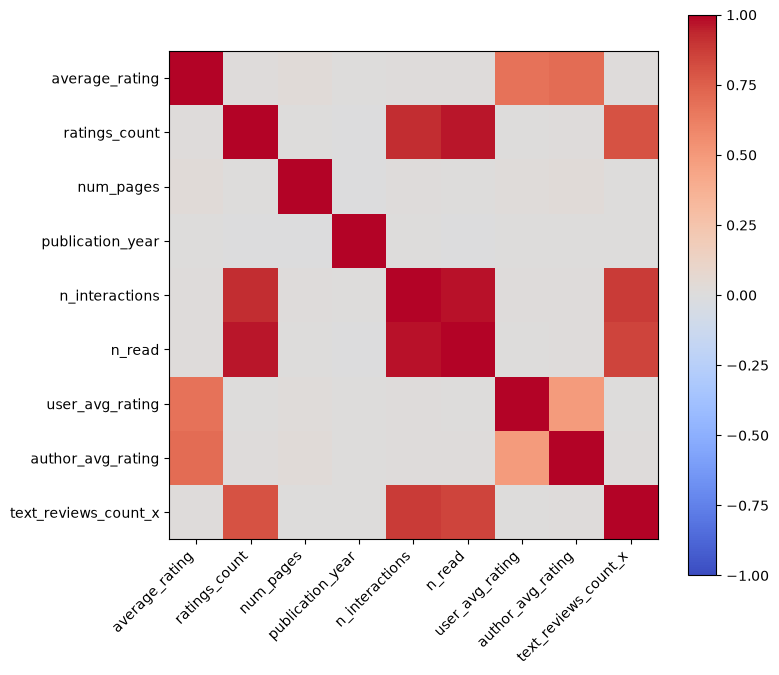

In [16]:
# Correlação entre as variáveis numéricas
corr = books_df[num_cols + ['author_avg_rating', 'text_reviews_count_x']].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr.columns)), corr.columns)
fig.colorbar(im)
plt.tight_layout()
plt.show()

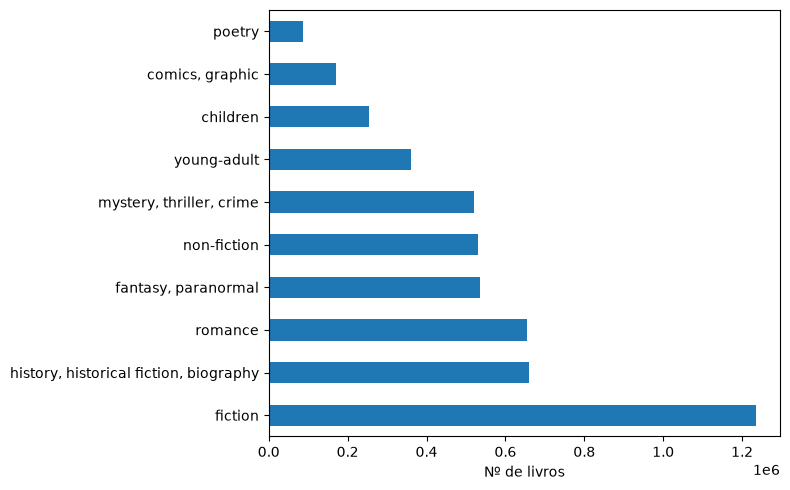

In [17]:
# Total de livros por gênero (contagem de shelves > 0)
genre_cols = genres.columns.drop('book_id')
(books_df[genre_cols] > 0).sum().sort_values(ascending=False).plot.barh(figsize=(8, 5))
plt.xlabel('Nº de livros')
plt.tight_layout()
plt.show()

### EDA aprofundada (padrões para o GMM)

- Objetivo: achar padrões e checar se as features são adequadas a um **Gaussian Mixture Model** (assume componentes ~gaussianos; por isso olhamos formas das distribuições após `log1p`, correlações e multimodalidade).
- Antes, uma cópia limpa só para análise (a limpeza final fica na etapa de Data Preparation).

In [18]:
genre_cols = list(genres.columns.drop('book_id'))
eda = books_df.copy()
eda[genre_cols] = eda[genre_cols].clip(lower=0)
eda.loc[~eda['publication_year'].between(1400, 2026), 'publication_year'] = np.nan
eda.loc[(eda['num_pages'] <= 0) | (eda['num_pages'] > 5000), 'num_pages'] = np.nan
eda['n_genres'] = (eda[genre_cols] > 0).sum(axis=1)
tot = eda[genre_cols].sum(axis=1)
eda['top_genre'] = np.where(tot > 0, eda[genre_cols].idxmax(axis=1), 'sem gênero')
eda['top_share'] = eda[genre_cols].max(axis=1) / tot.replace(0, np.nan)
eda['decade'] = (eda['publication_year'] // 10 * 10)
eda['log_ratings'] = np.log1p(eda['ratings_count'])
eda['log_inter'] = np.log1p(eda['n_interactions'])
eda['log_pages'] = np.log1p(eda['num_pages'])

**1. Livros por gênero dominante e quão 'puros' são** (misturas fortes favorecem GMM, que dá probabilidades por componente).

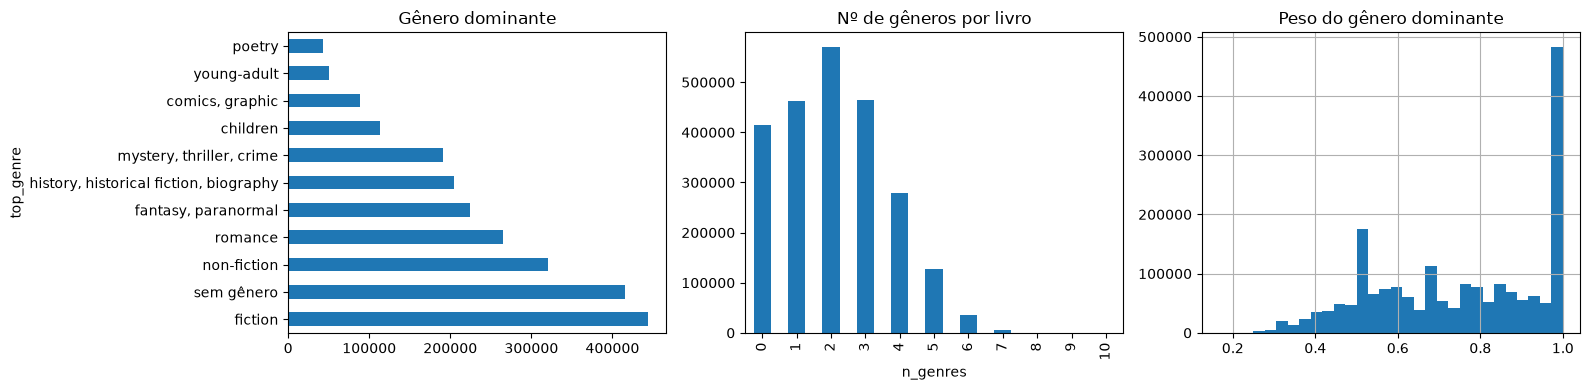

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
eda['top_genre'].value_counts().plot.barh(ax=ax[0], title='Gênero dominante')
eda['n_genres'].value_counts().sort_index().plot.bar(ax=ax[1], title='Nº de gêneros por livro')
eda['top_share'].hist(bins=30, ax=ax[2]); ax[2].set_title('Peso do gênero dominante')
plt.tight_layout(); plt.show()

**2. Nota e popularidade por gênero dominante.**

In [20]:
(eda[eda.ratings_count >= 10].groupby('top_genre')
     .agg(livros=('book_id','size'), nota=('average_rating','mean'),
          mediana_ratings=('ratings_count','median'), paginas=('num_pages','median'))
     .sort_values('nota', ascending=False).round(2))

,livros,nota,mediana_ratings,paginas
top_genre,,,,
poetry,26373,4.06,35.0,120.0
"fantasy, paranormal",173964,3.96,62.0,309.0
"comics, graphic",68502,3.92,56.0,165.0
non-fiction,235142,3.91,48.0,256.0
children,79710,3.91,47.0,40.0
sem gênero,104248,3.90,18.0,212.0
"history, historical fiction, biography",132818,3.89,38.0,304.0
romance,214343,3.88,69.0,256.0
"mystery, thriller, crime",140967,3.84,56.0,320.0


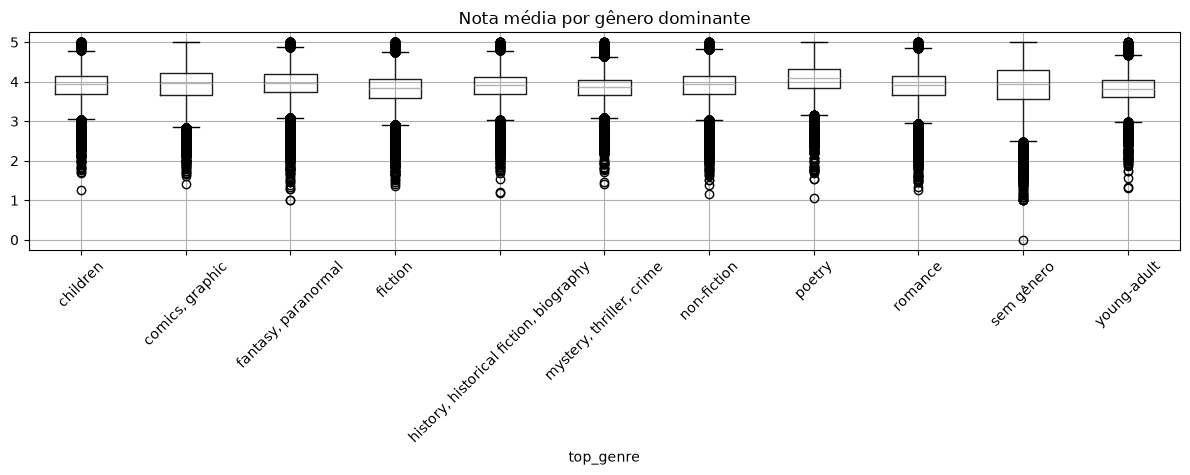

In [21]:
eda[eda.ratings_count >= 10].boxplot(column='average_rating', by='top_genre', figsize=(12, 5), rot=45)
plt.suptitle(''); plt.title('Nota média por gênero dominante'); plt.tight_layout(); plt.show()

**3. Popularidade x nota** (livros pouco avaliados têm nota instável — ruído para o clustering).

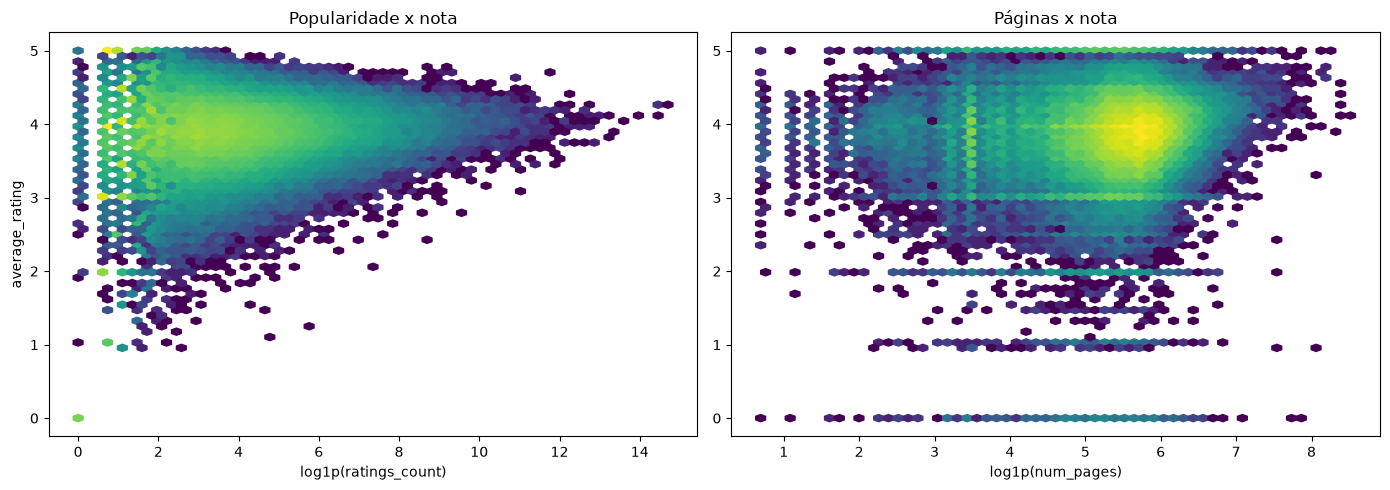

Livros com <5 avaliações: 21.1% | <20: 49.3%


In [22]:
s = eda.sample(200_000, random_state=0)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hexbin(s['log_ratings'], s['average_rating'], gridsize=60, bins='log', mincnt=1)
ax[0].set(xlabel='log1p(ratings_count)', ylabel='average_rating', title='Popularidade x nota')
ax[1].hexbin(s['log_pages'], s['average_rating'], gridsize=60, bins='log', mincnt=1)
ax[1].set(xlabel='log1p(num_pages)', title='Páginas x nota')
plt.tight_layout(); plt.show()
print('Livros com <5 avaliações:', f"{(eda.ratings_count < 5).mean():.1%}", '| <20:', f"{(eda.ratings_count < 20).mean():.1%}")

**4. Evolução temporal.**

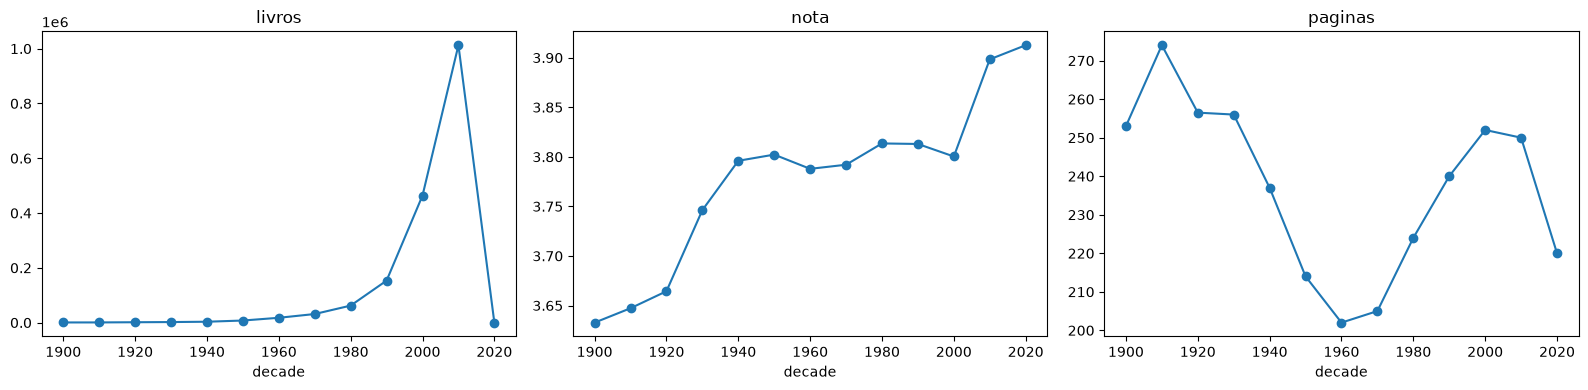

In [23]:
t = eda[eda.decade.between(1900, 2020)].groupby('decade').agg(livros=('book_id','size'), nota=('average_rating','mean'), paginas=('num_pages','median'))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, t.columns): t[c].plot(ax=a, marker='o', title=c)
plt.tight_layout(); plt.show()

**5. Co-ocorrência de gêneros** (proporção de livros com ambos os gêneros).

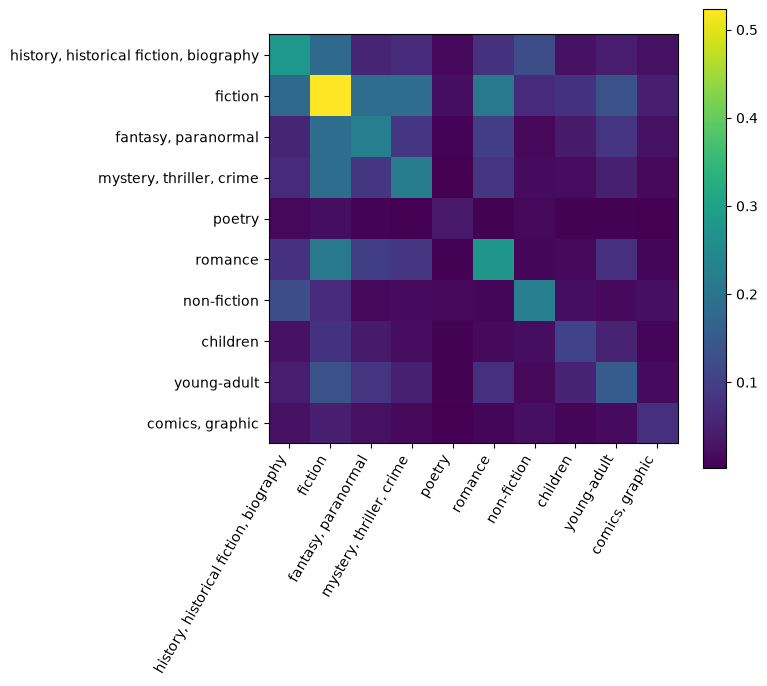

In [24]:
b = (eda[genre_cols] > 0).astype(int)
co = (b.T @ b) / len(b)
fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(co, cmap='viridis')
ax.set_xticks(range(len(genre_cols)), genre_cols, rotation=60, ha='right'); ax.set_yticks(range(len(genre_cols)), genre_cols)
fig.colorbar(im); plt.tight_layout(); plt.show()

**6. Checagem para o GMM:** formas após `log1p` (unimodal/simétrica = bom; muito assimétrica = transformar mais) e correlação entre features candidatas (alta correlação infla covariância e pede `covariance_type` restrito ou PCA).

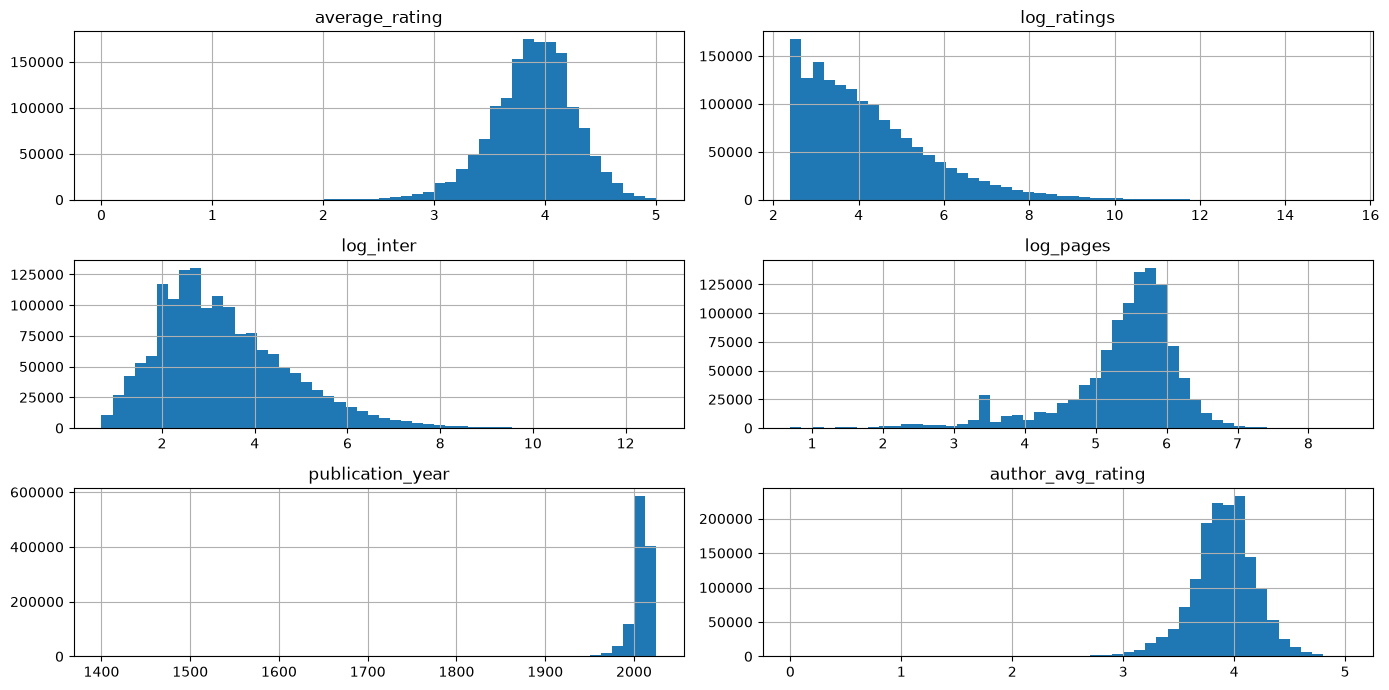

average_rating       -0.52
log_ratings           1.24
log_inter             0.94
log_pages            -1.56
publication_year    -13.39
author_avg_rating    -0.60
                   average_rating  log_ratings  log_inter  log_pages  \
average_rating               1.00         0.07       0.05       0.10   
log_ratings                  0.07         1.00       0.87       0.11   
log_inter                    0.05         0.87       1.00       0.14   
log_pages                    0.10         0.11       0.14       1.00   
publication_year             0.03        -0.01       0.07       0.00   
author_avg_rating            0.75         0.08       0.06       0.02   

                   publication_year  author_avg_rating  
average_rating                 0.03               0.75  
log_ratings                   -0.01               0.08  
log_inter                      0.07               0.06  
log_pages                      0.00               0.02  
publication_year               1.00             

In [25]:
cand = ['average_rating', 'log_ratings', 'log_inter', 'log_pages', 'publication_year', 'author_avg_rating']
rel = eda[eda.ratings_count >= 10]
rel[cand].hist(bins=50, figsize=(14, 7)); plt.tight_layout(); plt.show()
print(rel[cand].skew().round(2).to_string())
print(rel[cand].corr().round(2))

**7. Multimodalidade:** histogramas por gênero dominante — picos distintos indicam estrutura que o GMM pode capturar.

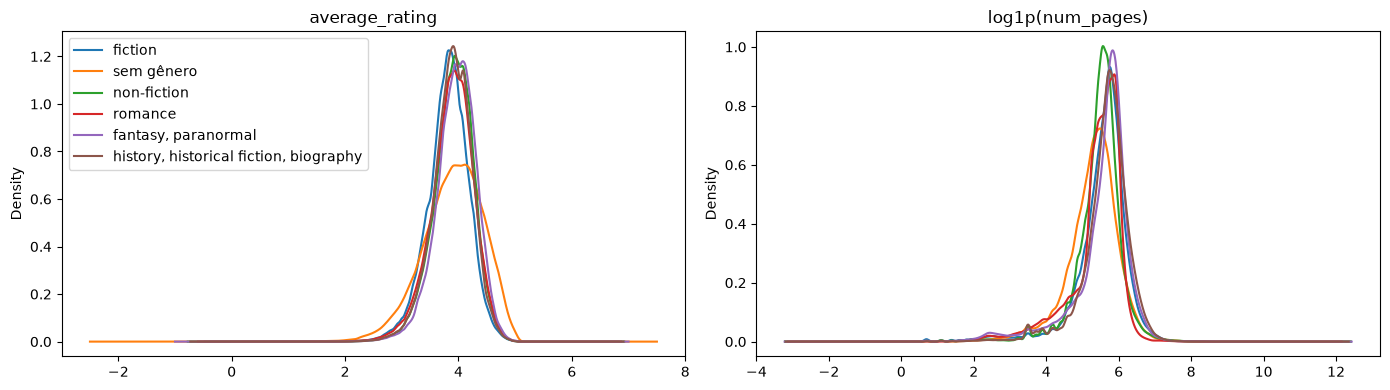

In [28]:
top = eda['top_genre'].value_counts().index[:6]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for g in top:
    d = rel[rel.top_genre == g]
    d['average_rating'].plot.kde(ax=ax[0], label=g); d['log_pages'].dropna().plot.kde(ax=ax[1], label=g)
ax[0].set_title('average_rating'); ax[1].set_title('log1p(num_pages)'); ax[0].legend(); plt.tight_layout(); plt.show()